In [9]:
# the first cell provides metadata (raw cell)

# Rocket Equation
At time $t_0$ to rocket starts to expel gas at a
_constant mass flow rate_ $R$ meassured in kg/s
and _exhaust velocity relative to the rocket_
$v_e$ in m/s.
$$
\frac{dv}{dt} = -\frac{F}{m(t)} = -\frac{Rv_e}{m(t)}
$$ {#eq-rocket-acc}
Integrating both sides of @eq-rocket-acc from 0
to $T$ we get

In [8]:
# in between the $$ in Markdown, there is a maths-term
# backslash frac gives a fraction

# Reading a Data file and plotting
*Copy from session 3 to use for session 4*

## Import needed files

In [2]:
import numpy # import needed files first
from matplotlib import pyplot #import from matplotlib the function for this code

## Open the files and read it, so it is usable

In [3]:
#create lists
time= []
absorption=[]

In [4]:
dataFile=open("data/pulse_data.csv")

In [5]:
!pwd #where am I

/home/kigr11/Spacemed-2026/kigr11


In [6]:
dataFile.readline() # if we run this, we read a line and then discard it, so jump to the next line
for line in dataFile.readlines() : # now the for loop starts with the second line
    line=line.split(",") #split at the comma
    time.append(float(line[0])) # 0 = before the comma; float because it would have been a string and you cannot plot strings, but floats
    absorption.append(float(line[1])) # 1 = after the comma
# if I reexecude the loop later, I might already be in the wrong line of the file

## Basic Plot

Text(0.5, 0, 'time [s]')

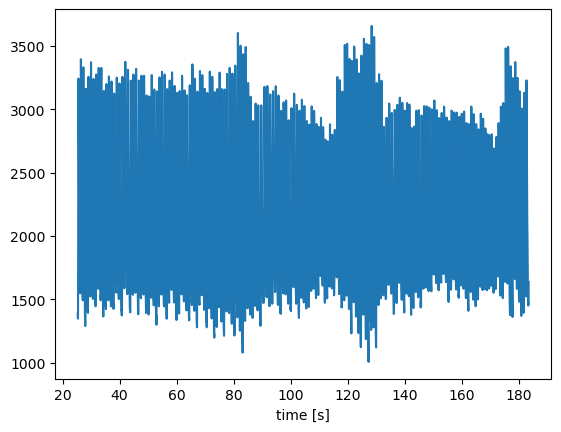

In [10]:
#| label: fig-dataset
#| fig-cap: "Measurements from an oxymetry sensor as a
#| function of time for 3 cycles"
pyplot.plot(time, absorption)
pyplot.xlabel("time [s]")

# Python Arrays

In [11]:
a=numpy.arange(10)+1

In [12]:
a.shape

(10,)

In [13]:
a.dtype

dtype('int64')

In [14]:
a.nbytes

80

In [15]:
b=numpy.array([[1,2,3],[4,5,6]])

In [16]:
b.shape

(2, 3)

In [20]:
b.T @ b

array([[17, 22, 27],
       [22, 29, 36],
       [27, 36, 45]])

In [21]:
a.T@ a # @= Vektorprodukt

385

In [22]:
a

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [25]:
numpy.max(a) # tells the biggest number

10

In [27]:
numpy.argmax(a) # tells the maximum position (starting at 0)

9

## Calculate pulse rate

$$H = \frac{T}{\Delta T_{\text{peaks}}}$$

In [41]:
absorption = numpy.array(absorption)
time = numpy.array(time)

In [31]:
w=50 # w = window (compare a point to the points around)

In [45]:
subset = absorption # now the subset is the whole data set. to practice you can e.g. choose the subset until 1000

In [43]:
peaks = []
for i in range (len(subset)): # the window moves along the dataset
    start = max(i-w, 0) # the point before is lower (i-w), 0 to include start of data
    end = min(i+w, len(subset)) # len(subset) to include the end of data
    window = subset[start:end]
    max_pos = numpy.argmax(window) + start # gives us the position inside the window, where the maximum is
    if i == max_pos:
        peaks.append(i)
print(peaks)

[96, 438, 774, 1142, 1502, 1851, 2211, 2578, 2929, 3291, 3651, 4003, 4356, 4724, 5092, 5452, 5828, 6252, 6647, 7022, 7414, 7787, 8159, 8548, 8919, 9272, 9626, 9992, 10344, 10703, 11076, 11429, 11781, 12153, 12514, 12855, 13183, 13531, 13891, 14247, 14587, 14927, 15286, 15662, 16034, 16388, 16746, 17087, 17413, 17751, 18109, 18465, 18812, 19167, 19505, 19842, 20173, 20535, 20880, 21246, 21628, 22024, 22393, 22767, 23144, 23483, 23822, 24177, 24527, 24872, 25237, 25664, 26106, 26516, 26920, 27319, 27693, 28070, 28439, 28787, 29136, 29488, 29888, 30262, 30639, 31005, 31345, 31686, 32034, 32381, 32719, 33052, 33385, 33712, 34012, 34312, 34632, 34953, 35275, 35601, 35948, 36305, 36660, 37008, 37344, 37671, 38002, 38340, 38662, 38983, 39317, 39672, 40020, 40376, 40745, 41102, 41448, 41797, 42140, 42477, 42822, 43191, 43556, 43921, 44323, 44698, 45040, 45387, 45736, 46058, 46378, 46696, 47019, 47343, 47700, 48084, 48440, 48791, 49161, 49524, 49863, 50206, 50556, 50895, 51231, 51576, 51940, 52

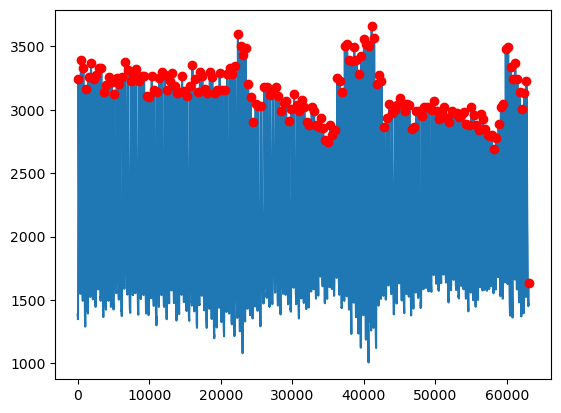

In [44]:
pyplot.plot(subset)
pyplot.plot(peaks, subset[peaks], "ro")

In [46]:
time_peaks = time[peaks]

In [47]:
delta_t = time_peaks[1:] -time_peaks[:-1]

In [48]:
hr = 60/ delta_t

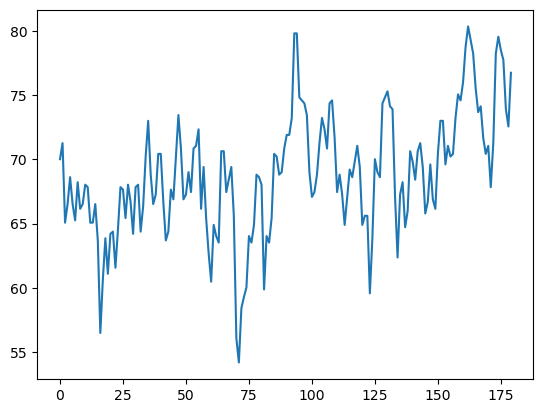

In [49]:
pyplot.plot(hr)

### Connotations

#### Graph with peaks

In [35]:
test = numpy.arange(20)

In [37]:
test

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [36]:
s= test[5:10] # create a subset

In [38]:
s

array([5, 6, 7, 8, 9])

=> the index of numbers in our window does change and not match the index in the whole array, so we need to add the lower bound of our subset (+ start in max_pos above)

#### Graph heart rate

In [50]:
peaks # to get a list of peaks

[96,
 438,
 774,
 1142,
 1502,
 1851,
 2211,
 2578,
 2929,
 3291,
 3651,
 4003,
 4356,
 4724,
 5092,
 5452,
 5828,
 6252,
 6647,
 7022,
 7414,
 7787,
 8159,
 8548,
 8919,
 9272,
 9626,
 9992,
 10344,
 10703,
 11076,
 11429,
 11781,
 12153,
 12514,
 12855,
 13183,
 13531,
 13891,
 14247,
 14587,
 14927,
 15286,
 15662,
 16034,
 16388,
 16746,
 17087,
 17413,
 17751,
 18109,
 18465,
 18812,
 19167,
 19505,
 19842,
 20173,
 20535,
 20880,
 21246,
 21628,
 22024,
 22393,
 22767,
 23144,
 23483,
 23822,
 24177,
 24527,
 24872,
 25237,
 25664,
 26106,
 26516,
 26920,
 27319,
 27693,
 28070,
 28439,
 28787,
 29136,
 29488,
 29888,
 30262,
 30639,
 31005,
 31345,
 31686,
 32034,
 32381,
 32719,
 33052,
 33385,
 33712,
 34012,
 34312,
 34632,
 34953,
 35275,
 35601,
 35948,
 36305,
 36660,
 37008,
 37344,
 37671,
 38002,
 38340,
 38662,
 38983,
 39317,
 39672,
 40020,
 40376,
 40745,
 41102,
 41448,
 41797,
 42140,
 42477,
 42822,
 43191,
 43556,
 43921,
 44323,
 44698,
 45040,
 45387,
 45736,


In [51]:
time[peaks] #create an array of time

array([ 25.5825874 ,  26.43943246,  27.28124514,  28.20323047,
        29.10517264,  29.97955546,  30.88149763,  31.80097756,
        32.68037117,  33.58732413,  34.48926629,  35.3711653 ,
        36.2555697 ,  37.17755503,  38.09954035,  39.00148252,
        39.94351101,  41.00579845,  41.99542943,  42.93495252,
        43.91706733,  44.85157963,  45.78358653,  46.75818515,
        47.68768666,  48.57209107,  49.45900086,  50.3759754 ,
        51.25787441,  52.15731118,  53.09182348,  53.97622788,
        54.85812689,  55.79013379,  56.69458136,  57.54892102,
        58.37069055,  59.24256798,  60.14451014,  61.03643073,
        61.888265  ,  62.74009927,  63.63953604,  64.58156452,
        65.51357143,  66.40048123,  67.2974126 ,  68.15175227,
        68.96851101,  69.81533448,  70.71226586,  71.60418645,
        72.47355848,  73.36297367,  74.20979715,  75.05411524,
        75.88340095,  76.79035391,  77.65471515,  78.57168968,
        79.52875054,  80.52088692,  81.44537764,  82.38

In [52]:
tp=time[peaks]

In [53]:
tp[1:]-tp[:-1] # = delta t

array([0.85684506, 0.84181269, 0.92198533, 0.90194217, 0.87438282,
       0.90194217, 0.91947993, 0.87939361, 0.90695296, 0.90194217,
       0.88189901, 0.8844044 , 0.92198533, 0.92198533, 0.90194217,
       0.94202849, 1.06228744, 0.98963099, 0.93952309, 0.9821148 ,
       0.9345123 , 0.93200691, 0.97459862, 0.92950151, 0.8844044 ,
       0.8869098 , 0.91697454, 0.88189901, 0.89943677, 0.9345123 ,
       0.8844044 , 0.88189901, 0.93200691, 0.90444756, 0.85433966,
       0.82176953, 0.87187743, 0.90194217, 0.89192059, 0.85183427,
       0.85183427, 0.89943677, 0.94202849, 0.93200691, 0.8869098 ,
       0.89693138, 0.85433966, 0.81675874, 0.84682348, 0.89693138,
       0.89192059, 0.86937203, 0.88941519, 0.84682348, 0.84431808,
       0.82928571, 0.90695296, 0.86436124, 0.91697454, 0.95706085,
       0.99213638, 0.92449072, 0.9370177 , 0.94453388, 0.84932887,
       0.84932887, 0.88941519, 0.87688822, 0.86436124, 0.91446914,
       1.06980363, 1.10738455, 1.02721191, 1.01217954, 0.99965